# Reproducir la red neuronal publicada: sus semillas, sus anchos y lo que vale su puntaje de hold-out

**Nivel 3: Estado del arte** · Requiere: 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites, 05-learned-arms/02-every-arm-and-why-each-one-refuses · Tiempo de lectura: unos 30 minutos

## Objetivos

Kulatilake, Hudaverdi y Wu 2012 entrenaron una red neuronal pequeña con este corpus y la informaron como la mejor de tres predictores en un hold-out de 12 tiros. El motor reproduce la red según su especificación publicada. Este notebook pregunta qué vale ese puntaje publicado cuando se varían la inicialización aleatoria de la red y su ancho oculto.

Al terminar habrá:

- reentrenado la red con 30 semillas y ubicado el puntaje publicado de hold-out entre ellas;
- reproducido la selección de ancho de la fuente y comparado los anchos que elige con los publicados;
- leído qué hace el ancho a la red con el sitio fuera, junto al nulo.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Esta celda aún no importa nada del notebook: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este notebook
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros de entrenamiento y el hold-out de 12 tiros con las predicciones impresas de la red | Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3; Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; los artículos nunca se distribuyen | el corpus y `bf.load_holdout(protocol="2012")` dentro del paquete `blastfrag` |
| El barrido de semillas y el barrido de anchos versionados | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json`, campos `network_seed_sweep` y `network_width_sweep` |

## Método

La red de Kulatilake et al. 2012 (https://doi.org/10.1007/s10706-012-9496-3, sección 5) está especificada con el detalle suficiente para reproducirla:

- una red por grupo de rigidez de la roca, cada una entrenada solo con las filas de ese grupo; el grupo viene del discriminante publicado;
- siete entradas, una capa oculta con activación logística, una salida, normalización mín-máx de entradas y objetivo (su Ec. 11);
- entrenamiento de Levenberg-Marquardt, ocho simulaciones por ancho promediadas, y un ancho oculto barrido de 6 a 15 y elegido en el hold-out por RMSE y correlación, lo que dio 9 para el primer grupo y 7 para el segundo.

Dos cosas se siguen de la especificación y el motor las declara en vez de corregirlas: la salida se acota al rango de los objetivos de entrenamiento, de modo que un sitio excluido con fragmentos más gruesos que todos los de entrenamiento no puede predecirse, y los anchos son los óptimos publicados, que la fuente eligió en su propio hold-out.

### Paso 1: el puntaje publicado y 30 semillas

La celda puntúa las predicciones impresas de la red en el hold-out de 12 tiros (la cifra publicada), y luego reentrena la reproducción del motor 30 veces, cada vez con una semilla distinta para la inicialización de pesos, con todo el corpus, y puntúa el hold-out. Toma cerca de medio minuto.

In [2]:
# Importaciones, el puntaje publicado de la columna impresa de la red y 30 reentrenamientos con semillas distintas
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from blastfrag.learned import PublishedNeuralNetwork

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
holdout = bf.load_holdout(protocol="2012")
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
printed = [bf.Prediction(method="published", blast_id=b.blast_id, x50_m=b.meta["published"]["nn_mean_2012"]) for b in holdout]
published = bf.score(holdout, printed).r2_identity
seed_scores = []
for seed in range(30):
    network = PublishedNeuralNetwork(seed=seed).fit(train)
    seed_scores.append(bf.score(holdout, network.predict(holdout)).r2_identity)
seed_scores = np.array(sorted(seed_scores))
print(f"publicado (columna impresa) r2_identity = {published:.4f}")
print(f"reproducido, 30 semillas: mín {seed_scores.min():.3f} | mediana {np.median(seed_scores):.3f} | máx {seed_scores.max():.3f}")
print("publicado sobre toda semilla:", bool(published > seed_scores.max()))
want = benchmark["network_seed_sweep"]
print("igual al barrido versionado:", bool(np.allclose(seed_scores, want["r2_identity"], atol=1e-9)))

publicado (columna impresa) r2_identity = 0.9096
reproducido, 30 semillas: mín 0.167 | mediana 0.340 | máx 0.636
publicado sobre toda semilla: True
igual al barrido versionado: True


La celda siguiente dibuja los 30 puntajes como una franja con el valor publicado, de modo que la posición de la cifra publicada se vea de un vistazo.

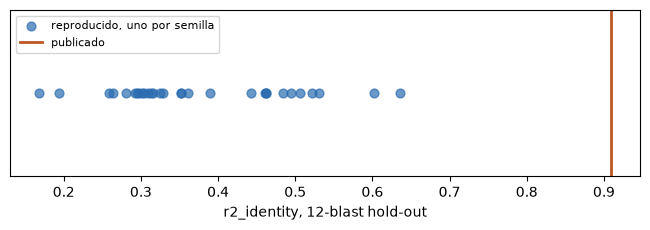

In [3]:
# Los 30 puntajes reproducidos contra el publicado
fig, ax = plt.subplots(figsize=(6.6, 2.4))
ax.scatter(seed_scores, np.zeros_like(seed_scores), s=40, alpha=0.7, color="#2b6cb0", label="reproducido, uno por semilla")
ax.axvline(published, color="#c05621", lw=2, label="publicado")
ax.set_yticks([])
ax.set_xlabel("r2_identity, 12-blast hold-out")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

### Paso 2: ¿la selección de ancho de la fuente cae en los anchos publicados?

`sweep_hidden_width` repite la selección: para cada ancho de 6 a 15 entrena la red y puntúa las filas de hold-out de cada grupo, y elige el ancho con menor RMSE. La celda imprime el ancho que elige por grupo junto al publicado y la tabla completa de RMSE de cada grupo, y luego compara los anchos elegidos con el barrido versionado.

In [4]:
# Repetir la selección de ancho de la fuente y comparar con los anchos publicados y el barrido versionado
sweep = PublishedNeuralNetwork(n_simulations=8, seed=0).sweep_hidden_width(train, holdout)
committed = benchmark["network_width_sweep"]["published_protocol"]
for group, entry in sweep.items():
    print(f"grupo {group}: este notebook elige {entry['best_hidden']} | publicado {entry['published_optimum']} | el barrido versionado elige {committed[str(group)]['best_hidden']}")
    row = {r["hidden"]: r for r in entry["table"]}
    print("   RMSE (m) por ancho:", {w: round(r["rmse"], 3) for w, r in row.items()})
    print("   correlación por ancho:", {w: round(r["correlation"], 2) for w, r in row.items()})

grupo 1: este notebook elige 8 | publicado 9 | el barrido versionado elige 8
   RMSE (m) por ancho: {6: 0.085, 7: 0.072, 8: 0.037, 9: 0.102, 10: 0.053, 11: 0.045, 12: 0.072, 13: 0.109, 14: 0.059, 15: 0.09}
   correlación por ancho: {6: 0.91, 7: 0.94, 8: 0.97, 9: 0.8, 10: 0.95, 11: 0.96, 12: 0.94, 13: 0.92, 14: 0.95, 15: 0.88}
grupo 2: este notebook elige 11 | publicado 7 | el barrido versionado elige 11
   RMSE (m) por ancho: {6: 0.125, 7: 0.133, 8: 0.153, 9: 0.14, 10: 0.142, 11: 0.106, 12: 0.157, 13: 0.157, 14: 0.125, 15: 0.147}
   correlación por ancho: {6: 0.91, 7: 0.92, 8: 0.91, 9: 0.9, 10: 0.91, 11: 0.88, 12: 0.9, 13: 0.92, 14: 0.89, 15: 0.9}


### Paso 3: el ancho con el sitio fuera

El barrido de anchos versionado también puntuó cada ancho, el mismo en ambos grupos, con un sitio fuera, junto al par publicado. La celda los lista con el nulo como referencia y dibuja el puntaje con sitio fuera contra el ancho.

anchos (grupo 1, grupo 2)     todos 97          91 con geometría
9, 7 (publicado)                -0.626                    -0.604
6, 6                            -0.605                    -0.630
7, 7                            -0.653                    -0.635
8, 8                            -0.626                    -0.562
9, 9                            -0.586                    -0.604
10, 10                          -0.902                    -0.955
11, 11                          -0.568                    -0.681
12, 12                          -1.027                    -1.169
13, 13                          -0.717                    -0.747
14, 14                          -1.257                    -1.296
15, 15                          -1.486                    -1.603
nulo (todos 97) = -0.216


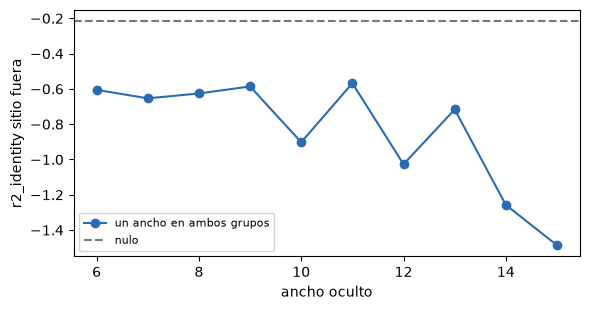

In [5]:
# Puntaje con sitio fuera de cada ancho, desde el barrido versionado, junto al par publicado y el nulo
table = benchmark["network_width_sweep"]["leave_one_site_out"]
null = benchmark["verdict"]["null_r2_identity"]
print(f"{'anchos (grupo 1, grupo 2)':<28}{'todos 97':>10}{'91 con geometría':>26}")
for row in table:
    label = f"{row['hidden']['1']}, {row['hidden']['2']}" + (" (publicado)" if row["published"] else "")
    print(f"{label:<28}{row['supports']['all']['r2_identity']:>10.3f}{row['supports']['geometry']['r2_identity']:>26.3f}")
print("nulo (todos 97) =", round(null, 3))

widths = [row["hidden"]["1"] for row in table if not row["published"]]
held = [row["supports"]["all"]["r2_identity"] for row in table if not row["published"]]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(widths, held, "o-", color="#2b6cb0", label="un ancho en ambos grupos")
ax.axhline(null, color="#777", ls="--", label="nulo")
ax.set_xlabel("ancho oculto")
ax.set_ylabel("r2_identity sitio fuera")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Estado del arte

- **Kulatilake, Hudaverdi y Wu 2012** (https://doi.org/10.1007/s10706-012-9496-3) es la referencia de la red: la especificación de la sección Método y un hold-out de 12 tiros en el que alcanza la mejor de las tres predicciones impresas.
- Las propias tablas de la fuente muestran que la elección del ancho es inestable: la correlación de un grupo oscila entre 0,11 y 0,81 entre anchos adyacentes, según la documentación del motor sobre la red.
- La red publicada es una sola instancia entrenada. El estado del arte informa un puntaje, sin dispersión sobre la inicialización y sin un sitio fuera.

## Resultados

**El puntaje publicado está sobre toda semilla reproducida.** Con 30 inicializaciones la reproducción puntúa entre cerca de 0,17 y 0,64 en el hold-out, con una mediana cercana a 0,34, mientras que las predicciones impresas puntúan 0,91. La reproducción sigue la especificación publicada; lo que no puede reproducir es ese único resultado impreso. Los 30 puntajes del notebook igualan el barrido versionado.

**La selección de ancho no cae en los anchos publicados.** Repetida con el procedimiento de la fuente, la selección elige un ancho distinto para cada grupo, y la tabla de RMSE se mueve mucho entre anchos vecinos: la elección descansa en ocho simulaciones y doce tiros de hold-out y no es estable.

**Con el sitio fuera ningún ancho ayuda.** Todo ancho de 6 a 15, y el par publicado, puntúa bajo cero, y los mejores anchos no lo hacen mejor que el nulo. Las redes más anchas lo hacen peor, lo que predice el sobreajuste a diez campañas. El ancho que la fuente optimizó en su propio hold-out no se traduce en un mejor resultado en una mina nueva.

**Qué no muestra esto.** No muestra que la red de la fuente se haya informado mal: una sola inicialización puede ser mejor que la mediana de muchas, y la fuente pudo elegir entre varias. Muestra que el número publicado no es una propiedad de la especificación, y que el producto por tanto no puede presentarlo como el desempeño esperado de la red.

## Resumen

- La red se reproduce según su especificación; su puntaje publicado de hold-out queda sobre las 30 semillas reproducidas, así que es una instancia favorable, no una expectativa.
- La selección de ancho de la fuente, repetida, elige otros anchos y es inestable entre vecinos.
- Con el sitio fuera, ningún ancho supera al nulo, y los más anchos son los peores.
- Siguiente: el tema 06 pregunta cómo responde una predicción cuando cambia el diseño.

## Referencias

- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (la red, su especificación y hold-out)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y el discriminante que encamina los grupos)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/